# 19 — From local chat to a checked map plan

**Question:** how can natural language become an inspectable geographic operation?

This is a **notebook-side teaching assistant**, not GeoLibre's native chat panel. A local language model may propose four settings. Python checks their types and ranges, a person reviews them, and the map displays an existing invented layer. No generated code, SQL, URLs or arbitrary tools are executed. Default outputs use a clearly labeled authored fixture.


## Start here: the question behind the code

**Can we inspect the map before applying AI's proposal?**

**What you will learn:** ask → check → preview → approve. The numbered reading guides below follow the actual code cells. Read a guide, predict the output, then run its cell with **Shift+Enter**. Run from top to bottom; changing an upstream value requires rerunning the cells that use it.

**GeoAI connection:** Optional local language-model inference; an authored fixture is used unless live mode is selected.

**Why this is useful:** Restricting the vocabulary makes proposed changes inspectable and mistakes easier to explain to a new learner.

**Where the work happens:** Ollama proposes four settings. Python checks them and computes selections; GeoLibre renders only after human approval.

![A chat request becomes a plan. Request a small JSON plan from an explicitly selected local model. Reject extra fields, imaginary layers and invalid values. Compute selection IDs without changing an existing map. Apply only after comparing the proposal with the intended request.](assets/learning/19/infographic.svg)

### Watch the idea unfold

[![Preview: A chat request becomes a plan — 32-second captioned walkthrough](assets/learning/19/poster.png)](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/lite/files/assets/learning/19/watch.html)

[▶ Watch the captioned mini-video and read its transcript](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/lite/files/assets/learning/19/watch.html) · [Launch this notebook](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/lite/lab/index.html?path=19_ollama_chat_to_map.ipynb) · [Read this Book chapter](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/notebooks/19_ollama_chat_to_map.html) · [Python and browser learning guide](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/learning-guide.html)

The video is a silent four-step teaching storyboard with player controls and captions. Open the companion page to play, pause, seek or download it. The local copy is bundled under `assets/learning/19/`; downloaded media can be played offline. The infographic and the text below cover the same ideas without a video player.

**Video transcript:**

1. **Ask (0–8 s):** Request a small JSON plan from an explicitly selected local model. Code landmark: `await propose_map(prompt)`.

2. **Check (8–16 s):** Reject extra fields, imaginary layers and invalid values. Code landmark: `validate_plan(proposal['plan'])`.

3. **Preview (16–24 s):** Compute selection IDs without changing an existing map. Code landmark: `preview_plan(plan)`.

4. **Approve (24–32 s):** Apply only after comparing the proposal with the intended request. Code landmark: `APPROVE_MAP = True`.


### Code guide 1 — Prepare the browser and local-service tools

**Read the Python:** The runtime check installs browser-compatible map and plotting packages only in Pyodide. Imports expose the local helper functions. No network request to Ollama occurs in this setup cell.

**Look for:** Plotting, map-building and optional local-model functions are ready.

**Pause and try:** Which packages render a map, and which helper will contact Ollama only when explicitly called?


In [1]:
import sys, json
from pathlib import Path
if sys.platform == "emscripten":
    import micropip
    await micropip.install(["geolibre==3.0.0", "anywidget"])
    from pyodide import loadPackage
    await loadPackage("matplotlib")
import matplotlib.pyplot as plt
from matplotlib.patches import Polygon
from IPython.display import display, Markdown, FileLink
from ollama_mapping import (BASE_URL, MODEL, FIXTURE_PLAN, COLORS, diagnose,
    synthetic_cells, validate_plan, preview_plan, apply_plan, demo_map, propose_map)
print("Browser" if sys.platform == "emscripten" else "Ordinary Python", "— no model request made")


Ordinary Python — no model request made


### Code guide 2 — Ask for a small, typed plan

**Read the Python:** The default branch labels a hand-authored example. Only the live branch calls local Ollama. The helper sends a schema, checks the installed model, rejects remote-backed models, and clears stale results before a retry.

**Look for:** A four-field plan and an explicit fixture/live provenance label.

**Pause and try:** Find which line makes the actual model request. Why is this not model training in Pyodide?


In [2]:
LIVE_MODEL = False
prompt = "Show synthetic heat cells with heat proxy at least 39 in orange and tilt the map to 45 degrees."
proposal = None  # Never reuse an earlier success after a failed live call.
if LIVE_MODEL:
    proposal = await propose_map(prompt, model=MODEL, base_url=BASE_URL)
else:
    proposal = {"source": "hand-authored fixture; NOT a captured AI answer", "prompt": prompt,
                "plan": dict(FIXTURE_PLAN)}
print(json.dumps(proposal, indent=2))


{
  "source": "hand-authored fixture; NOT a captured AI answer",
  "prompt": "Show synthetic heat cells with heat proxy at least 39 in orange and tilt the map to 45 degrees.",
  "plan": {
    "layer": "synthetic_cells",
    "minimum_heat": 39,
    "color": "orange",
    "pitch": 45
  }
}


### Code guide 3 — Preview with deterministic code

**Read the Python:** Independent validation rejects unknown fields and unsafe values. The list of selected IDs is computed from the invented grid, not supplied by the language model. The chart is a dry run.

**Look for:** Seven selected cells for the supplied cutoff of 39.

**Pause and try:** Check each requested setting. Could valid JSON still describe the wrong map?


Computed selection: 7 of 12 cells ['cell-0-2', 'cell-0-3', 'cell-1-2', 'cell-1-3', 'cell-2-1', 'cell-2-2', 'cell-2-3']
Check all four settings against your request: {'layer': 'synthetic_cells', 'minimum_heat': 39, 'color': 'orange', 'pitch': 45}


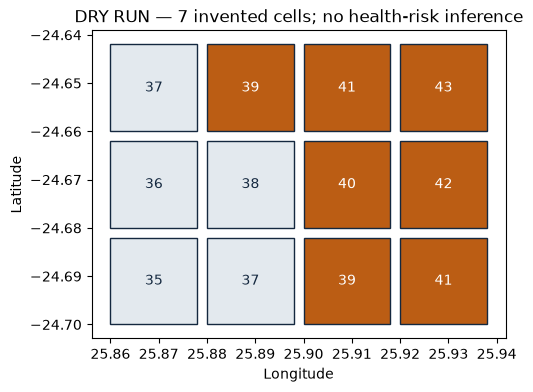

In [3]:
plan = validate_plan(proposal["plan"])
preview = preview_plan(plan)  # Dry run: inspect, do not mutate an existing map.
selected_ids = [f["id"] for f in preview["features"]]
print("Computed selection:", len(selected_ids), "of 12 cells", selected_ids)
print("Check all four settings against your request:", plan)
fig, ax = plt.subplots(figsize=(7, 4))
for feature in synthetic_cells()["features"]:
    chosen = feature["id"] in selected_ids
    ring = feature["geometry"]["coordinates"][0]
    ax.add_patch(Polygon(ring, facecolor=COLORS[plan["color"]] if chosen else "#e3e9ee",
                         edgecolor="#14283f"))
    ax.text(ring[0][0]+.009, ring[0][1]+.009, str(feature["properties"]["heat_proxy_c"]),
            ha="center", va="center", color="white" if chosen else "#14283f")
ax.autoscale(); ax.set_aspect("equal")
ax.set(title=f"DRY RUN — {len(selected_ids)} invented cells; no health-risk inference",
       xlabel="Longitude", ylabel="Latitude")
plt.show()


## Human review is a separate step

For the supplied request, expect `minimum_heat=39`, `color='orange'`, `pitch=45`, and **7** cells. Schema validity alone cannot establish that a model understood your words. If you change the prompt, change your expected answer independently. A failure stops here; the code does not silently substitute the fixture for a failed live response.


### Code guide 4 — Approve this proposal

**Read the Python:** A separate Boolean gate controls application. `approved_map=None` clears a previous result. The helper uses known GeoLibre operations, not model-generated Python or SQL.

**Look for:** Default: no map applied. After review and approval: a new GeoLibre map.

**Pause and try:** Change the prompt, rerun, and review again before approving. Approval is not a permanent trust decision.


In [4]:
APPROVE_MAP = False  # Change only after inspecting THIS proposal and its dry run.
approved_map = None
if APPROVE_MAP:
    approved_features = apply_plan(plan, approved=True)
    approved_map = demo_map(plan)
    display(approved_map)
else:
    print("Not applied. Review the plan before changing APPROVE_MAP to True.")


Not applied. Review the plan before changing APPROVE_MAP to True.


### Code guide 5 — Preserve a small audit

**Read the Python:** The audit records provenance, prompt, plan, computed IDs and approval state. The map project is exported only if one was approved. These files stay local until you download or share them.

**Look for:** An inspectable JSON record; no automatic upload.

**Pause and try:** What would you remove before sharing an audit of a real project?


In [5]:
audit = {"source": proposal["source"], "model": proposal.get("model"),
         "prompt": prompt, "plan": plan, "selected_ids": selected_ids,
         "approved": APPROVE_MAP, "data": "synthetic teaching grid", "clinical_use": False}
export_dir = Path("exports"); export_dir.mkdir(exist_ok=True)
(export_dir / "ollama-plan-audit.json").write_text(json.dumps(audit, indent=2), encoding="utf-8")
if approved_map is not None:
    (export_dir / "ollama-approved.geolibre.json").write_text(
        json.dumps(approved_map.to_project(), indent=2), encoding="utf-8")
print("Audit saved locally. Inspect prompts and outputs before downloading or sharing.")


Audit saved locally. Inspect prompts and outputs before downloading or sharing.


**Try a follow-up:** [lab 20](20_ollama_evidence_review.ipynb) carries forward the validated plan, compares counts and challenges misleading claims. The restricted notebook helper cannot search STAC or answer arbitrary GIS questions; use [labs 07–08](07_stac_browser_catalogs.ipynb) for catalog discovery, with source and access checks.


## Sources, privacy and next step

The polygons and Celsius-like `heat_proxy_c` values are **invented teaching data**, not measured heat, clinic locations, disease rates or climate projections. GeoLibre renders the map; Ollama runs optional inference on your computer, not inside Pyodide. Basemaps and the hosted viewer still use the network. Do not enter patient records, credentials or confidential prompts.

Read the [advanced chapter](https://jltobias.github.io/JupyterLite-GeoLibre-GeoAI/advanced/ollama-assistant.html), [GeoLibre AI Assistant guide](https://geolibre.app/user-guide/ai-assistant/), [Ollama chat API](https://docs.ollama.com/api/chat) and [structured-output documentation](https://docs.ollama.com/capabilities/structured-outputs). These are independent teaching examples, not a Horizon integration. [Global Nature Watch Horizon](https://horizon.globalnaturewatch.org/) supplies interaction inspiration, not these data or model results. Sources accessed 11 October 2026.


## Make sense of the result

![Valid JSON means the AI understood me? It may still choose the wrong valid settings. I will compare the dry run with my request.](assets/learning/19/cartoon.svg)

**Cartoon transcript:** Valid JSON means the AI understood me? → It may still choose the wrong valid settings. → I will compare the dry run with my request.

**Explain it to a colleague:** Who calculates the selected-cell count: the model or Python?

<details><summary>Check your reasoning</summary>

Python calculates it from the actual fixture. The model proposes parameters; the human checks their meaning.

</details>

Write three sentences: **I used…** (source and units), **the code computed…** (method), and **I can conclude…** (plus a remaining question). Point to the map, chart or table that supports each claim.

All new teaching illustrations are original schematics. Their marks and fictional dialogue are explanatory, not observations, fitted predictions or captured AI conversations. The existing citation cells identify the analytical data.


## GeoLibre creator and software attribution

GeoLibre is developed by **Qiusheng Wu and contributors**. Recommended citation: Wu, Q. (2026). *GeoLibre: A lightweight, cloud-native GIS platform for visualizing, exploring, and analyzing geospatial data.* Zenodo. [doi:10.5281/zenodo.20785400](https://doi.org/10.5281/zenodo.20785400). See [the official citation guidance](https://geolibre.app/citation/) and [source and MIT license](https://github.com/opengeos/GeoLibre). These browser lessons pin the Python builders to `geolibre==3.0.0`; the independently hosted viewer may change. This repository supplies the JupyterLite adapter and teaching materials, not the upstream GIS. Keep the original dataset, demo-author and basemap credits when sharing a result.
